# CALCE CX2 — FlowState-inspired SOH forecasting benchmark

**Goal:** test whether an elapsed-time-aware state-space encoder and functional-basis decoder improve next-cycle battery SOH forecasting relative to matched Transformer baselines. All models use **five selected charging features**, identical windows, and battery-disjoint train/validation/test splits.

**Important:** This is an **independent FlowState-inspired architecture**, *not* the official IBM FlowState/S5 reproduction or pretrained foundation model. We implement a diagonal continuous-time exponential state update and a functional-basis horizon decoder. We do **not** claim sampling-rate equivariance or transfer of ICML benchmark results.

**Reference:** Graf et al., *FlowState: Sampling-Rate-Equivariant Time-Series Forecasting*, ICML 2026: https://proceedings.mlr.press/v306/graf26a.html

### Fair experimental design
- Next-cycle / multi-horizon forecasts from **past cycles only** (no target-cycle features, no target timestamps, no prior SOH as input).
- Disjoint batteries: train original 5 cells; validation CX2_36; test CX2_38. Keep test for reporting, not tuning.
- Training uses `train_final_filtered.csv` if available. Preserve source cycle numbers; **no sequences across deleted cycles, gaps >24 hours, or nonmonotonic timestamps**.
- Four neural architectures plus two last-observation regression controls: Direct Transformer, time-aware Transformer, time-aware SSM+MLP, time-aware SSM+functional-basis decoder.
- Timesteps from observed cycle starts indicate elapsed **recording time**, *not* verified rest. Forecast query is future **cycle offset**, not known future wall time.
- Evaluation: MAE, RMSE, MAPE, R² per horizon, per seed; parameter counts, training wall time, and saved predictions.


In [1]:
# Cell 1 — Dependencies. Run only if required.
# %pip install torch numpy pandas scikit-learn matplotlib
import os, json, copy, time, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print('PyTorch:',torch.__version__)
print('CUDA available:', torch.cuda.is_available())


PyTorch: 2.11.0+cu128
CUDA available: True


In [2]:
# Cell 2 — Configuration
DATA_DIR = Path(r'C:\Projects\Battery_Soh\pre processed ready to use data')
# For smoke checks outside Windows, change DATA_DIR to your extracted CSV directory.
TRAIN_NAME = 'train_final_filtered.csv'
VAL_NAME = 'validation.csv'
TEST_NAME = 'test.csv'
FEATURES = ['cc_duration_s','cv_duration_s','dva_peak','ic_peak_voltage','ic_peak_width']
TARGET = 'soh'
LOOKBACK = 12
HORIZONS = (1,3,5)  # Future cycle offsets; predicts y at n+h using only x through n
MAX_OBSERVED_GAP_H = 24.0  # Segment split only; never interpret unknown gap as rest
BATCH_SIZE = 128
HIDDEN = 48
LR = 1e-3
WEIGHT_DECAY = 1e-4
MAX_EPOCHS = 70
PATIENCE = 12
SEEDS = [42,123,2026]
MODE = 'full'  # 'smoke' for fast verification with fewer windows/epochs
OUTPUT_DIR = DATA_DIR / 'flowstate_inspired_results'
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
if DEVICE.type == 'cpu':
    torch.set_num_threads(min(4, max(1,os.cpu_count() or 1)))
print('Device:',DEVICE,'Output directory:', OUTPUT_DIR)


Device: cuda Output directory: C:\Projects\Battery_Soh\pre processed ready to use data\flowstate_inspired_results


In [3]:
# Cell 3 — Read and validate CSVs. Only train file is filtered.
if not (DATA_DIR / TRAIN_NAME).exists():
    raise FileNotFoundError(f'Missing filtered training CSV: {DATA_DIR / TRAIN_NAME}. Do not silently substitute original data.')
def load_split(name):
    d=pd.read_csv(DATA_DIR/name)
    required=['battery','cycle_ordinal','cycle_start',TARGET]+FEATURES
    absent=[c for c in required if c not in d.columns]
    if absent: raise ValueError(f'{name}: missing columns {absent}')
    d['cycle_start']=pd.to_datetime(d['cycle_start'], errors='raise')
    d=d.sort_values(['battery','cycle_ordinal','cycle_start']).reset_index(drop=True)
    if d[required].isna().any().any(): raise ValueError(f'{name}: null fields in required columns')
    if d.duplicated(['battery','cycle_ordinal']).any(): raise ValueError(f'{name}: duplicate battery-cycle ordinal')
    if not np.isfinite(d[FEATURES+[TARGET]].to_numpy('float64')).all():raise ValueError(f'{name}: non-finite numeric entries')
    return d
train_df=load_split(TRAIN_NAME)
val_df=load_split(VAL_NAME)
test_df=load_split(TEST_NAME)
assert set(train_df.battery).isdisjoint(set(val_df.battery))
assert set(train_df.battery).isdisjoint(set(test_df.battery))
assert set(val_df.battery).isdisjoint(set(test_df.battery))
for name,d in [('train',train_df),('validation',val_df),('test',test_df)]:
    print(name, 'rows',len(d),'cells',d.battery.unique().tolist())


train rows 7690 cells ['CX2_16', 'CX2_33', 'CX2_34', 'CX2_35', 'CX2_37']
validation rows 1743 cells ['CX2_36']
test rows 1477 cells ['CX2_38']


In [4]:
# Cell 4 — Training-only normalization, timestamp checks, and sequences
scaler=StandardScaler().fit(train_df[FEATURES])
# dt normalization uses only genuine consecutive train transitions

def segments(df):
    for battery,g in df.groupby('battery', sort=True):
        g=g.sort_values('cycle_ordinal').copy()
        dcy=g.cycle_ordinal.diff()
        dt=g.cycle_start.diff().dt.total_seconds()/3600
        breaks=(dcy.ne(1) | dt.le(0) | dt.gt(MAX_OBSERVED_GAP_H)).fillna(True)
        for _,sub in g.groupby(breaks.cumsum()):
            if len(sub) >= LOOKBACK+min(HORIZONS):
                yield str(battery),sub.reset_index(drop=True)

# Normalize time using strictly valid contiguous training transitions
valid_deltas=[]
for _,sub in segments(train_df):
    diff=sub.cycle_start.diff().dt.total_seconds().dropna().to_numpy()/3600
    valid_deltas.extend(diff.tolist())
DT_SCALE_H=float(np.median(valid_deltas))
assert DT_SCALE_H>0
print('Training median adjacent elapsed hours:',DT_SCALE_H)

class CycleWindowDataset(Dataset):
    def __init__(self, df, mode='full'):
        self.arr=[]
        maxh=max(HORIZONS)
        for battery,sub in segments(df):
            xs=scaler.transform(sub[FEATURES]).astype('float32')
            start=sub['cycle_start']
            dt=np.zeros(len(sub),dtype=np.float32)
            dt[1:]=(start.diff().dt.total_seconds().to_numpy()[1:]/3600 / DT_SCALE_H).astype('float32')
            # dt at first observed input is set to 1 (unknown earlier interval).
            dt[0]=1.0
            ords=sub.cycle_ordinal.to_numpy(dtype=int)
            y=sub[TARGET].to_numpy('float32')
            for end in range(LOOKBACK-1,len(sub)-maxh):
                # x through end; y at end+h only. No current/future y or features leak into inputs.
                for horizon in HORIZONS:
                    target_idx=end+horizon
                    self.arr.append((xs[end-LOOKBACK+1:end+1],dt[end-LOOKBACK+1:end+1],
                                     np.float32(horizon),np.float32(y[target_idx]),battery,int(ords[target_idx]),int(ords[end])))
        if mode=='smoke':
            rng=np.random.default_rng(1729)
            n=min(150,len(self.arr)); indices=rng.choice(len(self.arr),size=n,replace=False)
            self.arr=[self.arr[i] for i in sorted(indices)]
    def __len__(self):return len(self.arr)
    def __getitem__(self,i):return self.arr[i]

tr=CycleWindowDataset(train_df,MODE)
va=CycleWindowDataset(val_df,MODE)
te=CycleWindowDataset(test_df,MODE)
print('windows train/validation/test:',len(tr),len(va),len(te))
assert min(len(tr),len(va),len(te))>0
print('Example: horizon, target cycle, last input cycle:',tr[0][2],tr[0][5],tr[0][6]); assert tr[0][5]-tr[0][6]==int(tr[0][2])

pd.DataFrame({'feature':FEATURES,'training_mean':scaler.mean_, 'training_scale':scaler.scale_}).to_csv(OUTPUT_DIR/'scaler.csv',index=False)
with open(OUTPUT_DIR/'config.json','w') as fp:
    json.dump({'features':FEATURES,'train_name':TRAIN_NAME,'lookback':LOOKBACK,'horizons':HORIZONS,
               'gap_threshold_hours':MAX_OBSERVED_GAP_H,'dt_training_median_hours':DT_SCALE_H,
               'mode':MODE,'seeds':SEEDS,'note':'time gaps do not imply rest; horizon is in cycle offsets'},fp,indent=2)


Training median adjacent elapsed hours: 3.8841666666666668
windows train/validation/test: 8067 1929 1491
Example: horizon, target cycle, last input cycle: 1.0 47 46


## Architecture comparison

The SSM update is an **independent diagonal time-discretized state transition**:

\[
\mathbf{z}_{k}=e^{-\Delta t_k/\boldsymbol\tau}\odot\mathbf z_{k-1}
+\left(1-e^{-\Delta t_k/\boldsymbol\tau}\right)\odot \tanh(W\mathbf x_k+b).
\]

This is *not the official S5 block*. A learned state vector then produces either (a) an MLP query head, or (b) coefficients in a functional basis \(\sum_j c_j\phi_j(h)\) for an arbitrary **future cycle offset** \(h\). We do not supply target-cycle timestamps (which would generally be unknown in live forecasting).


In [5]:
# Cell 5 — Model definitions
import torch.nn.functional as F

class HorizonMLP(nn.Module):
    def __init__(self, hidden):
        super().__init__(); self.net=nn.Sequential(nn.Linear(hidden+1,hidden),nn.GELU(),nn.Linear(hidden,1))
    def forward(self,z,h):
        u=(h.view(-1,1)/max(HORIZONS))
        return self.net(torch.cat([z,u],dim=1)).squeeze(-1)

class TransformerModel(nn.Module):
    def __init__(self,time_aware):
        super().__init__(); self.time_aware=time_aware
        self.emb=nn.Linear(len(FEATURES)+(1 if time_aware else 0),HIDDEN)
        self.pos=nn.Parameter(torch.zeros(1,LOOKBACK,HIDDEN))
        layer=nn.TransformerEncoderLayer(HIDDEN,nhead=4,dim_feedforward=HIDDEN*2,dropout=0.1,batch_first=True,norm_first=True)
        self.encoder=nn.TransformerEncoder(layer,num_layers=2,enable_nested_tensor=False)
        self.head=HorizonMLP(HIDDEN)
    def forward(self,x,dt,h):
        if self.time_aware:
            # log dampens large observed elapsed times; only past timestamps used
            x=torch.cat([x,torch.log1p(dt).unsqueeze(-1)],dim=-1)
        z=self.encoder(self.emb(x)+self.pos)[:,-1]
        return self.head(z,h)

class DiagonalTimeSSM(nn.Module):
    def __init__(self):
        super().__init__()
        self.input=nn.Linear(len(FEATURES),HIDDEN)
        self.log_tau=nn.Parameter(torch.linspace(-1,3,HIDDEN)) # time units: train median hours
        self.norm=nn.LayerNorm(HIDDEN)
    def forward(self,x,dt):
        state=x.new_zeros(x.size(0),HIDDEN)
        tau=F.softplus(self.log_tau)+0.05
        for k in range(x.size(1)):
            decay=torch.exp(-dt[:,k:k+1]/tau.unsqueeze(0))
            state=decay*state+(1-decay)*torch.tanh(self.input(x[:,k]))
        return self.norm(state)

class FunctionalBasisDecoder(nn.Module):
    def __init__(self):
        super().__init__(); self.coeff=nn.Linear(HIDDEN,6)
    def forward(self,state,h):
        u=h.view(-1,1)/max(HORIZONS)
        basis=torch.cat([torch.ones_like(u),u,u**2,
                         torch.sin(torch.pi*u),torch.cos(torch.pi*u),torch.exp(-u)],dim=1)
        return (self.coeff(state)*basis).sum(dim=1)

class SSMModel(nn.Module):
    def __init__(self,functional_decoder=False):
        super().__init__(); self.ssm=DiagonalTimeSSM()
        self.head=FunctionalBasisDecoder() if functional_decoder else HorizonMLP(HIDDEN)
    def forward(self,x,dt,h):return self.head(self.ssm(x,dt),h)

MODEL_FACTORIES={
    'direct_transformer':lambda:TransformerModel(False),
    'time_transformer':lambda:TransformerModel(True),
    'time_ssm_mlp':lambda:SSMModel(False),
    'time_ssm_fbd':lambda:SSMModel(True),
}
for model_name,fac in MODEL_FACTORIES.items():
    model=fac()
    print(model_name, 'parameters',sum(p.numel() for p in model.parameters() if p.requires_grad))


direct_transformer parameters 41233
time_transformer parameters 41281
time_ssm_mlp parameters 2881
time_ssm_fbd parameters 726


In [6]:
# Cell 6 — Unit tests: no target leak, horizon queries, gradient flow
xb,dtb,hb,yb,batb,tarb,lastb = next(iter(DataLoader(tr,batch_size=min(8,len(tr)),shuffle=False)))
assert torch.all((tarb-lastb)==hb.int())
for name,factory in MODEL_FACTORIES.items():
    model=factory().to(DEVICE)
    yp=model(xb.to(DEVICE),dtb.to(DEVICE),hb.to(DEVICE))
    assert yp.shape==yb.shape and torch.isfinite(yp).all(),name
    yp.square().mean().backward()
    assert any(p.grad is not None and torch.isfinite(p.grad).all() for p in model.parameters())
print('All model forward/backward and future-target indexing checks passed')


All model forward/backward and future-target indexing checks passed


In [7]:
# Cell 7 — Reproducible training and evaluation
from collections import defaultdict

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():torch.cuda.manual_seed_all(seed)

def data_loader(ds, shuffle=False):return DataLoader(ds,batch_size=BATCH_SIZE,shuffle=shuffle,num_workers=0)

def predict(model,ds):
    model.eval(); predictions=[]; truths=[]; rows=[]
    with torch.no_grad():
        for x,dt,h,y,battery,target_cycle,last_cycle in data_loader(ds):
            ph=model(x.to(DEVICE),dt.to(DEVICE),h.to(DEVICE)).cpu().numpy()
            predictions.extend(ph.tolist()); truths.extend(y.numpy().tolist())
            rows.extend(zip(list(battery),target_cycle.numpy().tolist(),last_cycle.numpy().tolist(),h.numpy().tolist()))
    out=pd.DataFrame(rows,columns=['battery','target_cycle','last_input_cycle','horizon'])
    out['actual_soh']=truths;out['predicted_soh']=predictions
    out['error']=out.predicted_soh-out.actual_soh
    return out

def metrics(frame):
    yy=frame.actual_soh.to_numpy(); pp=frame.predicted_soh.to_numpy()
    return dict(RMSE=float(np.sqrt(np.mean((yy-pp)**2))),MAE=float(np.mean(np.abs(yy-pp))),
                MAPE=float(np.mean(np.abs((yy-pp)/np.maximum(np.abs(yy),1e-6)))*100),
                R2=float(r2_score(yy,pp)) if len(yy)>1 and np.var(yy)>0 else np.nan,
                n=int(len(yy)))

def train_one(model_name,seed):
    set_seed(seed)
    model=MODEL_FACTORIES[model_name]().to(DEVICE)
    optimizer=torch.optim.AdamW(model.parameters(),lr=LR,weight_decay=WEIGHT_DECAY)
    best=float('inf'); best_epoch=-1; bad=0; weights=None; hist=[]; t0=time.perf_counter()
    epochs=2 if MODE=='smoke' else MAX_EPOCHS
    patience=2 if MODE=='smoke' else PATIENCE
    for epoch in range(1,epochs+1):
        model.train(); train_errors=[]
        for x,dt,h,y,*_ in data_loader(tr,True):
            x=x.to(DEVICE);dt=dt.to(DEVICE);h=h.to(DEVICE);y=y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            yh=model(x,dt,h)
            loss=F.mse_loss(yh,y)
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.0)
            optimizer.step()
            train_errors.append(float(loss.item())*len(y))
        train_mse=sum(train_errors)/len(tr)
        val=metrics(predict(model,va))
        hist.append(dict(epoch=epoch,train_rmse=np.sqrt(train_mse),validation_rmse=val['RMSE']))
        if val['RMSE'] < best-1e-6:
            best=val['RMSE'];best_epoch=epoch;bad=0;weights=copy.deepcopy(model.state_dict())
        else:
            bad+=1
        if epoch==1 or epoch%10==0 or bad>=patience:
            print(f'{model_name} seed={seed} ep={epoch} trainRMSE={np.sqrt(train_mse):.5f} valRMSE={val["RMSE"]:.5f} best={best:.5f}')
        if bad>=patience:break
    model.load_state_dict(weights)
    duration=time.perf_counter()-t0
    pfx=f'{model_name}_seed{seed}'
    torch.save({'model_state':model.state_dict(),'model':model_name,'seed':seed,'epoch':best_epoch,
                'features':FEATURES,'lookback':LOOKBACK,'horizons':HORIZONS},OUTPUT_DIR/f'{pfx}.pt')
    pd.DataFrame(hist).to_csv(OUTPUT_DIR/f'{pfx}_history.csv',index=False)
    result=[]
    for split,ds in [('validation',va),('test',te)]:
        pred=predict(model,ds)
        pred.to_csv(OUTPUT_DIR/f'{pfx}_{split}_predictions.csv',index=False)
        for horizon,chunk in pred.groupby('horizon'):
            result.append(dict(model=model_name,seed=seed,split=split,horizon=int(horizon),
                               best_epoch=best_epoch,train_seconds=duration,
                               parameters=sum(p.numel() for p in model.parameters() if p.requires_grad),**metrics(chunk)))
    return result


In [8]:
# Cell 8 — Main experiment
models=list(MODEL_FACTORIES)
seeds=[42] if MODE=='smoke' else SEEDS
all_rows=[]
for model_name in models:
    for seed in seeds:
        all_rows.extend(train_one(model_name,seed))
all_metrics=pd.DataFrame(all_rows)
all_metrics.to_csv(OUTPUT_DIR/'metrics_all_runs.csv',index=False)
print('Completed',len(models)*len(seeds),'training runs')


direct_transformer seed=42 ep=1 trainRMSE=0.17903 valRMSE=0.01939 best=0.01939
direct_transformer seed=42 ep=10 trainRMSE=0.01435 valRMSE=0.01710 best=0.01623
direct_transformer seed=42 ep=20 trainRMSE=0.01059 valRMSE=0.01493 best=0.01493
direct_transformer seed=42 ep=30 trainRMSE=0.00951 valRMSE=0.01499 best=0.01383
direct_transformer seed=42 ep=40 trainRMSE=0.00918 valRMSE=0.01770 best=0.01342
direct_transformer seed=42 ep=48 trainRMSE=0.00864 valRMSE=0.02229 best=0.01342
direct_transformer seed=123 ep=1 trainRMSE=0.19711 valRMSE=0.05468 best=0.05468
direct_transformer seed=123 ep=10 trainRMSE=0.01727 valRMSE=0.02253 best=0.01978
direct_transformer seed=123 ep=20 trainRMSE=0.01201 valRMSE=0.01786 best=0.01727
direct_transformer seed=123 ep=30 trainRMSE=0.01102 valRMSE=0.01754 best=0.01442
direct_transformer seed=123 ep=38 trainRMSE=0.01070 valRMSE=0.02047 best=0.01442
direct_transformer seed=2026 ep=1 trainRMSE=0.21656 valRMSE=0.03956 best=0.03956
direct_transformer seed=2026 ep=10 t

In [9]:
# Cell 9 — Simple forecasting controls (same inputs and targets; no future features)
# These are last-observation feature baselines, not the previous current-cycle SOH estimators.
from sklearn.linear_model import LinearRegression, Ridge

def tabular_features(ds, feature_ids):
    X=[]; y=[]; meta=[]
    for seq,dt,h,target,battery,target_cycle,last_input_cycle in ds.arr:
        X.append(np.r_[seq[-1,feature_ids],h/max(HORIZONS)])
        y.append(target)
        meta.append((battery,target_cycle,last_input_cycle,h))
    return np.asarray(X),np.asarray(y),meta

for model_name,feat_ids,reg in [
    ('ols_last_CC_CV',[0,1],LinearRegression()),
    ('ridge_last_five',list(range(5)),Ridge(alpha=1.0)),
]:
    xtr,ytr,_=tabular_features(tr,feat_ids)
    start=time.perf_counter();reg.fit(xtr,ytr);duration=time.perf_counter()-start
    for split,ds in [('validation',va),('test',te)]:
        xx,yy,meta=tabular_features(ds,feat_ids)
        yp=reg.predict(xx)
        frame=pd.DataFrame(meta,columns=['battery','target_cycle','last_input_cycle','horizon'])
        frame['actual_soh']=yy;frame['predicted_soh']=yp
        frame['error']=frame.predicted_soh-frame.actual_soh
        frame.to_csv(OUTPUT_DIR/f'{model_name}_{split}_predictions.csv',index=False)
        for horizon,grp in frame.groupby('horizon'):
            all_rows.append(dict(model=model_name,seed=0,split=split,horizon=int(horizon),best_epoch=0,
                                 train_seconds=duration,parameters=len(reg.coef_)+1,**metrics(grp)))
all_metrics=pd.DataFrame(all_rows)
all_metrics.to_csv(OUTPUT_DIR/'metrics_all_runs.csv',index=False)
print('Added leakage-safe last-cycle OLS and Ridge controls.')


Added leakage-safe last-cycle OLS and Ridge controls.


In [10]:
# Cell 10 — Validation leaderboard; use validation ONLY for model choice
summary=(all_metrics.groupby(['split','model','horizon'],as_index=False)
         .agg(RMSE_mean=('RMSE','mean'),RMSE_std=('RMSE','std'),MAE_mean=('MAE','mean'),
              MAPE_mean=('MAPE','mean'),R2_mean=('R2','mean'),training_seconds=('train_seconds','mean')))
summary.to_csv(OUTPUT_DIR/'metrics_summary.csv',index=False)
print('Validation leaderboard per horizon:')
for h in HORIZONS:
    print('horizon:',h)
    display(summary.query('split=="validation" and horizon==@h').sort_values('RMSE_mean'))
print('Test summary for reporting only, not hyperparameter selection:')
display(summary.query('split=="test"').sort_values(['horizon','RMSE_mean']))


Validation leaderboard per horizon:
horizon: 1


,split,model,horizon,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,training_seconds
21,validation,ols_last_CC_CV,1,0.008425,NaN,0.006087,0.816423,0.995022,0.003096
24,validation,ridge_last_five,1,0.008486,NaN,0.006183,0.842224,0.994949,0.001119
30,validation,time_ssm_mlp,1,0.011420,0.001310,0.008792,1.218088,0.990773,105.106052
18,validation,direct_transformer,1,0.012743,0.000633,0.009372,1.365275,0.988592,106.167803
33,validation,time_transformer,1,0.014994,0.004158,0.011387,1.622623,0.983423,39.038652
27,validation,time_ssm_fbd,1,0.022317,0.006479,0.017697,2.481731,0.963105,51.022569


horizon: 3


,split,model,horizon,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,training_seconds
22,validation,ols_last_CC_CV,3,0.010678,NaN,0.007842,1.061544,0.992002,0.003096
25,validation,ridge_last_five,3,0.010721,NaN,0.008144,1.117316,0.991937,0.001119
31,validation,time_ssm_mlp,3,0.012494,0.001122,0.009424,1.314682,0.988992,105.106052
19,validation,direct_transformer,3,0.013988,0.000497,0.010283,1.480497,0.986265,106.167803
34,validation,time_transformer,3,0.015934,0.003463,0.011693,1.678780,0.981630,39.038652
28,validation,time_ssm_fbd,3,0.018883,0.005242,0.014465,2.049742,0.973705,51.022569


horizon: 5


,split,model,horizon,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,training_seconds
23,validation,ols_last_CC_CV,5,0.011711,NaN,0.008247,1.130295,0.990353,0.003096
26,validation,ridge_last_five,5,0.011758,NaN,0.008753,1.209606,0.990276,0.001119
32,validation,time_ssm_mlp,5,0.012814,0.001064,0.009708,1.355186,0.988398,105.106052
20,validation,direct_transformer,5,0.014529,0.000576,0.010562,1.516684,0.985137,106.167803
35,validation,time_transformer,5,0.018017,0.005696,0.013536,1.929322,0.975646,39.038652
29,validation,time_ssm_fbd,5,0.025077,0.005965,0.018651,2.650530,0.954099,51.022569


Test summary for reporting only, not hyperparameter selection:


,split,model,horizon,RMSE_mean,RMSE_std,MAE_mean,MAPE_mean,R2_mean,training_seconds
15,test,time_transformer,1,0.011651,0.000821,0.009430,1.251338,0.990216,39.038652
0,test,direct_transformer,1,0.013823,0.001212,0.011874,1.527289,0.986202,106.167803
3,test,ols_last_CC_CV,1,0.014227,NaN,0.013066,1.662979,0.985459,0.003096
6,test,ridge_last_five,1,0.016711,NaN,0.015961,2.044877,0.979940,0.001119
12,test,time_ssm_mlp,1,0.017329,0.001640,0.015357,1.932672,0.978299,105.106052
9,test,time_ssm_fbd,1,0.029683,0.007141,0.023416,3.181779,0.934264,51.022569
1,test,direct_transformer,3,0.014507,0.001145,0.012202,1.576805,0.984852,106.167803
16,test,time_transformer,3,0.014538,0.002114,0.011906,1.549940,0.984636,39.038652
4,test,ols_last_CC_CV,3,0.015291,NaN,0.013674,1.746405,0.983241,0.003096
7,test,ridge_last_five,3,0.017680,NaN,0.016516,2.122904,0.977595,0.001119


In [11]:
# Cell 11 — Paired validation differences vs time-aware Transformer
base=all_metrics.query('split=="validation" and model=="time_transformer"')[['seed','horizon','RMSE']].rename(columns={'RMSE':'time_transformer_RMSE'})
paired=all_metrics.query('split=="validation"').merge(base,on=['seed','horizon'])
paired['RMSE_improvement_pct']=100*(paired.time_transformer_RMSE-paired.RMSE)/paired.time_transformer_RMSE
paired.to_csv(OUTPUT_DIR/'paired_validation_comparison.csv',index=False)
display(paired.groupby(['model','horizon'])['RMSE_improvement_pct'].agg(['mean','std','min','max']))


mean        std         min        max
model              horizon                                             
direct_transformer 1         9.340578  31.368353  -25.581890  35.125844
                   3         8.614371  25.100735  -19.840581  27.615070
                   5        13.121696  30.616142  -19.943993  40.487051
time_ssm_fbd       1       -65.563837  90.546374 -160.388507  19.991091
                   3       -26.866570  58.824213  -85.623555  32.024641
                   5       -56.321900  85.074343 -149.541256  17.125394
time_ssm_mlp       1        21.310768  13.679524    7.344554  34.684339
                   3        19.911315  11.660233    7.802607  31.064239
                   5        24.626285  20.283137    7.011900  46.801564
time_transformer   1         0.000000   0.000000    0.000000   0.000000
                   3         0.000000   0.000000    0.000000   0.000000
                   5         0.000000   0.000000    0.000000   0.000000

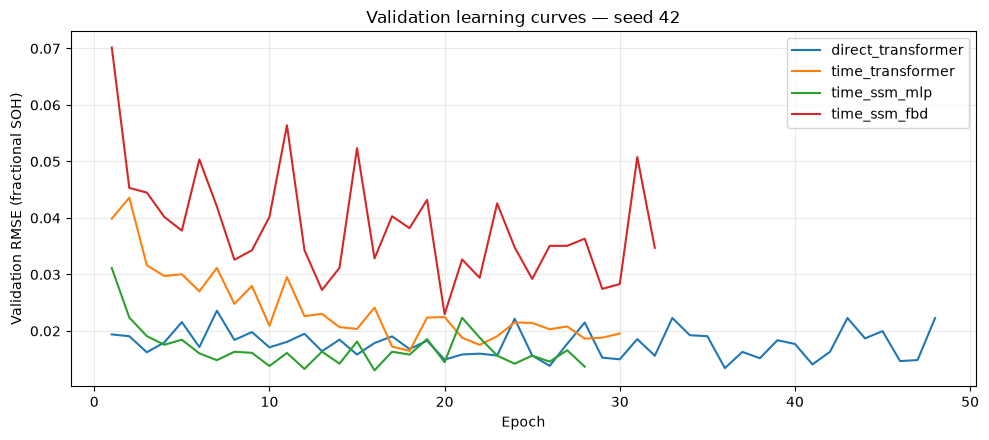

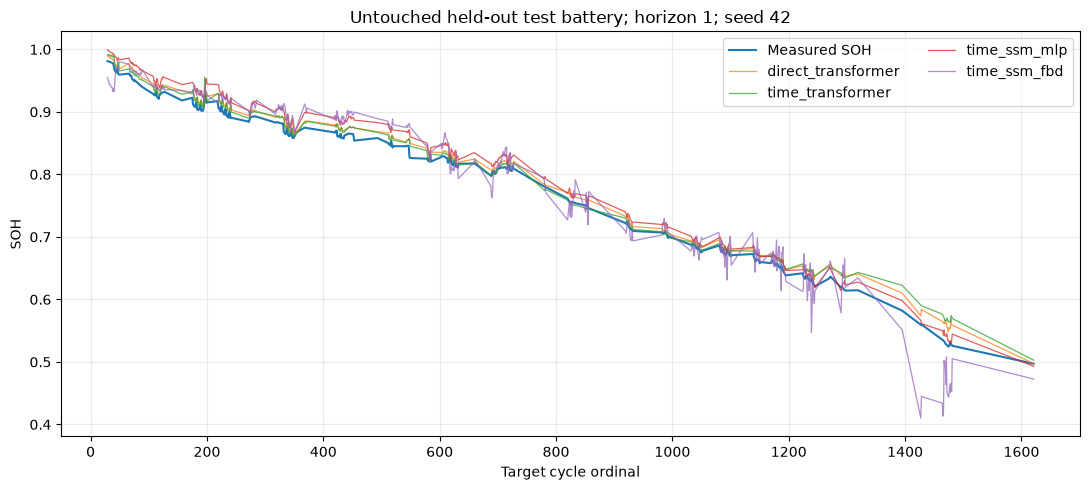

In [12]:
# Cell 12 — Plot validation curves and forecasts
fig,ax=plt.subplots(figsize=(10,4.5))
for model_name in models:
    hs=pd.read_csv(OUTPUT_DIR/f'{model_name}_seed{seeds[0]}_history.csv')
    ax.plot(hs.epoch,hs.validation_rmse,label=model_name)
ax.set(xlabel='Epoch',ylabel='Validation RMSE (fractional SOH)',title='Validation learning curves — seed '+str(seeds[0]))
ax.grid(alpha=0.25);ax.legend();fig.tight_layout()
fig.savefig(OUTPUT_DIR/'validation_learning_curves.png',dpi=150);plt.show()

h1=HORIZONS[0]
fig,ax=plt.subplots(figsize=(11,5))
first=pd.read_csv(OUTPUT_DIR/f'{models[0]}_seed{seeds[0]}_test_predictions.csv').query('horizon==@h1').sort_values('target_cycle')
ax.plot(first.target_cycle,first.actual_soh,label='Measured SOH',lw=1.5)
for model_name in models:
    preds=pd.read_csv(OUTPUT_DIR/f'{model_name}_seed{seeds[0]}_test_predictions.csv').query('horizon==@h1').sort_values('target_cycle')
    ax.plot(preds.target_cycle,preds.predicted_soh,label=model_name,lw=0.9,alpha=0.75)
ax.set(xlabel='Target cycle ordinal',ylabel='SOH',title=f'Untouched held-out test battery; horizon {h1}; seed {seeds[0]}')
ax.grid(alpha=0.25);ax.legend(ncol=2);fig.tight_layout()
fig.savefig(OUTPUT_DIR/'test_predictions_h1.png',dpi=150);plt.show()


## Interpretation checklist (read before making claims)

1. **Time advantage:** `time_transformer` vs `direct_transformer` establishes whether observed intervals matter at all.
2. **SSM advantage:** `time_ssm_mlp` vs `time_transformer` tests a different time-aware encoder; compare parameter counts and runtime.
3. **Functional basis advantage:** `time_ssm_fbd` vs `time_ssm_mlp` isolates the decoder, not the official FlowState architecture.
4. **Cross-battery validation:** results are from five training cells and just one validation cell. Do *not* claim general cross-battery gains. An outer leave-one-cell-out analysis remains necessary.
5. **Fluctuation audit:** the statistical training filter is *not* proof of erroneous samples.
6. **No future leakage:** future SOH is the target, **never an input**; future charging features/timestamps are not used; inputs remain contiguous after filtering.
7. **No proof of true sampling-rate equivariance:** this implementation uses time-discretized exponential memory, not S5 + the paper's full sampling-rate-controlled decoder and pretraining procedure.
8. **Task separation:** previous current-cycle estimation RMSE (0.012754) is **not** a matched comparator to these next-cycle/multi-cycle forecasting results.

### Suggested follow-up
Run a fold-based experiment using the same architecture implementations, selecting epochs/architecture using only training-fold inner validation. A **persistence** forecaster would additionally require past SOH, which the current four neural models do not receive. A matched last-observation CC/CV OLS and five-feature Ridge control are already included. Until then, don't claim SOTA or a novel breakthrough.
